# Notebook 00 — Shared Infrastructure
## Video Captioning Project · Run this first, then share outputs with team

**Owner:** Any one team member (run once)

This notebook sets up everything that all member notebooks depend on:
- Installs packages
- Downloads & parses MSVD and MSR-VTT annotations
- Downloads / synthesises video files
- Defines shared utilities: `sample_frames`, datasets, `CaptionEvaluator`, `run_evaluation`
- Saves all shared objects to disk so member notebooks are fully self-contained

**Do not add model code here.**

| File saved | Used by |
|-----------|----------|
| `shared/msvd_captions.json` | All member notebooks |
| `shared/msrvtt_captions.json` | All member notebooks |
| `shared/msvd_splits.json` | All member notebooks |
| `shared/msrvtt_splits.json` | All member notebooks |
| `shared/msvd_ok_ids.json` | All member notebooks |
| `shared/msrvtt_ok_ids.json` | All member notebooks |
| `results/` (empty dir) | All member notebooks write here |


In [1]:
from google.colab import drive
drive.mount('/content/drive')

# After mounting the drive, you can change the current working directory to your specific project folder.

import os

project_path = '/content/drive/MyDrive/CS4015_GenAI_Project'
os.makedirs(project_path, exist_ok=True)
os.chdir(project_path)

print(f"Changed current working directory to: {os.getcwd()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Changed current working directory to: /content/drive/MyDrive/CS4015_GenAI_Project


---
## §1 — Package Installation

In [2]:
import subprocess, sys

packages = [
    "torch torchvision torchaudio",
    "transformers>=4.40.0",
    "accelerate>=0.27.0",
    "bitsandbytes",
    "sentencepiece protobuf",
    "decord",
    "opencv-python-headless",
    "Pillow numpy pandas matplotlib tqdm",
    "pycocoevalcap pycocotools",
    "ftfy regex einops",
    "git+https://github.com/openai/CLIP.git",
    "rouge-score nltk av",
]
for pkg in packages:
    print(f"  {pkg.split()[0]}...", end=" ", flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkg.split()])
    print("ok")
print("\n✅ All packages installed.")


  torch... ok
  transformers>=4.40.0... ok
  accelerate>=0.27.0... ok
  bitsandbytes... ok
  sentencepiece... ok
  decord... ok
  opencv-python-headless... ok
  Pillow... ok
  pycocoevalcap... ok
  ftfy... ok
  git+https://github.com/openai/CLIP.git... ok
  rouge-score... ok

✅ All packages installed.


---
## §2 — Directory Structure & Config

In [3]:
import os, json, random, warnings
import numpy as np
import torch
import cv2
warnings.filterwarnings("ignore")

# ── GPU check ────────────────────────────────────────────────────────────────
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU : {props.name}  ({props.total_memory/1024**3:.1f} GB)")
else:
    print("No GPU detected — running on CPU")

# ── Shared directories ────────────────────────────────────────────────────────
SHARED_DIR      = "./shared"
MSVD_VIDEO_DIR  = "./videos/msvd"
MSRVTT_VIDEO_DIR= "./videos/msrvtt"
RESULTS_DIR     = "./results"

for d in [SHARED_DIR, MSVD_VIDEO_DIR, MSRVTT_VIDEO_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Global constants (must match across all notebooks) ────────────────────────
SEED            = 42
NUM_FRAMES      = 8
MAX_CAPTION_LEN = 30
EVAL_SUBSET     = 100

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE == "cuda": torch.cuda.manual_seed_all(SEED)

# Save constants for member notebooks
cfg = {"SEED":SEED,"NUM_FRAMES":NUM_FRAMES,
       "MAX_CAPTION_LEN":MAX_CAPTION_LEN,"EVAL_SUBSET":EVAL_SUBSET,
       "DEVICE":DEVICE,
       "MSVD_VIDEO_DIR":MSVD_VIDEO_DIR,
       "MSRVTT_VIDEO_DIR":MSRVTT_VIDEO_DIR,
       "RESULTS_DIR":RESULTS_DIR}
with open(os.path.join(SHARED_DIR,"config.json"),"w") as f:
    json.dump(cfg, f, indent=2)
print("Config saved to shared/config.json")
print(f"  DEVICE={DEVICE} | NUM_FRAMES={NUM_FRAMES} | EVAL_SUBSET={EVAL_SUBSET}")


No GPU detected — running on CPU
Config saved to shared/config.json
  DEVICE=cpu | NUM_FRAMES=8 | EVAL_SUBSET=100


---
## §3 — MSVD Annotations & Video Preparation

In [4]:
import os
import json
import pickle
import random

caption_path = os.path.join(SHARED_DIR, "raw-captions.pkl")
train_path   = os.path.join(SHARED_DIR, "train_list.txt")
val_path     = os.path.join(SHARED_DIR, "val_list.txt")
test_path    = os.path.join(SHARED_DIR, "test_list.txt")


with open(caption_path, "rb") as f:
    raw = pickle.load(f)

msvd_captions = {}

# raw is usually dict: video_id -> list of captions
for vid, caps in raw.items():
    if isinstance(caps, list):
        msvd_captions[vid] = caps
    else:
        msvd_captions[vid] = [str(caps)]

print("Total videos:", len(msvd_captions))


def load_list(path):
    with open(path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

train_ids = load_list(train_path)
val_ids   = load_list(val_path)
test_ids  = load_list(test_path)


train_ids = [v for v in train_ids if v in msvd_captions]
val_ids   = [v for v in val_ids if v in msvd_captions]
test_ids  = [v for v in test_ids if v in msvd_captions]

train_ids = sorted(set(train_ids))
val_ids   = sorted(set(val_ids))
test_ids  = sorted(set(test_ids))


msvd_splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

print(
    f"MSVD SPLITS → "
    f"train={len(train_ids)} "
    f"val={len(val_ids)} "
    f"test={len(test_ids)}"
)


os.makedirs(SHARED_DIR, exist_ok=True)

with open(os.path.join(SHARED_DIR, "msvd_captions.json"), "w") as f:
    json.dump(msvd_captions, f)

with open(os.path.join(SHARED_DIR, "msvd_splits.json"), "w") as f:
    json.dump(msvd_splits, f, indent=2)

print("✅ MSVD cleaned + saved successfully")

Total videos: 1970
MSVD SPLITS → train=1200 val=100 test=670
✅ MSVD cleaned + saved successfully


In [5]:
# ── Prepare MSVD video files ─────────────────────────────────────────────────
try:
    subprocess.run(["yt-dlp","--version"],capture_output=True,check=True)
except Exception:
    subprocess.run([sys.executable,"-m","pip","install","-q","yt-dlp"])

def create_synthetic_video(path, n_frames=30, fps=10, h=224, w=224):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    wr = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for _ in range(n_frames):
        wr.write(np.random.randint(0,255,(h,w,3),dtype=np.uint8))
    wr.release()

def download_video(vid_id, url, out_dir, res=360):
    p = os.path.join(out_dir, f"{vid_id}.mp4")
    if os.path.exists(p): return True
    if not url or "synthetic" in url: return False
    r = subprocess.run(
        ["yt-dlp", url, "-f", f"bestvideo[height<={res}]+bestaudio/best",
         "--merge-output-format","mp4","-o",p,"--quiet","--socket-timeout","15"],
        capture_output=True, timeout=60)
    return r.returncode == 0

from tqdm.notebook import tqdm

test_ids = msvd_splits["test"][:EVAL_SUBSET]
msvd_ok  = []
print(f"Preparing {len(test_ids)} MSVD test videos...")
for vid in tqdm(test_ids, desc="MSVD"):
    vpath = os.path.join(MSVD_VIDEO_DIR, f"{vid}.mp4")
    if os.path.exists(vpath):
        msvd_ok.append(vid); continue
    if not download_video(vid, "", MSVD_VIDEO_DIR):
        create_synthetic_video(vpath)
    msvd_ok.append(vid)

with open(os.path.join(SHARED_DIR,"msvd_ok_ids.json"),"w") as f:
    json.dump(msvd_ok, f)
print(f"MSVD ready: {len(msvd_ok)} videos. Saved msvd_ok_ids.json")


Preparing 100 MSVD test videos...


MSVD:   0%|          | 0/100 [00:00<?, ?it/s]

MSVD ready: 100 videos. Saved msvd_ok_ids.json


---
## §4 — MSR-VTT Annotations & Video Preparation

In [6]:
import os
import json
import pandas as pd

json_path = os.path.join(SHARED_DIR, "MSRVTT_data.json")

# ── 1. Load captions JSON ────────────────────────────────
with open(json_path, "r", encoding="utf-8") as f:
    raw = json.load(f)

msrvtt_captions = {}
for v in raw["videos"]:
    vid = v["video_id"]
    msrvtt_captions[vid] = []

for s in raw["sentences"]:
    vid = s["video_id"]
    if vid in msrvtt_captions:
        msrvtt_captions[vid].append(s["caption"])

print("Total videos:", len(msrvtt_captions))

# ── 2. Load official split files (IMPORTANT FIX) ─────────

train7k = pd.read_csv(os.path.join(SHARED_DIR, "MSRVTT_train.7k.csv"))
train9k = pd.read_csv(os.path.join(SHARED_DIR, "MSRVTT_train.9k.csv"))
test_df = pd.read_csv(os.path.join(SHARED_DIR, "MSRVTT_JSFUSION_test.csv"))

# column name varies across versions
def get_vid(df):
    for col in df.columns:
        if "video_id" in col.lower():
            return df[col].astype(str).tolist()
    return df.iloc[:, 0].astype(str).tolist()

train_ids = list(set(get_vid(train7k) + get_vid(train9k)))
test_ids  = get_vid(test_df)
train_ids = [x for x in train_ids if x not in test_ids]

# validation is usually carved from train
split_point = int(0.9 * len(train_ids))
val_ids = train_ids[split_point:]
train_ids = train_ids[:split_point]

msrvtt_splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

print(f"MSR-VTT SPLITS → train={len(train_ids)} val={len(val_ids)} test={len(test_ids)}")

# ── 3. URLs placeholder (not provided in this dataset) ──
msrvtt_urls = {}

for v in raw.get("videos", []):
    vid = v.get("video_id")
    url = v.get("url", "")

    if vid:
        msrvtt_urls[vid] = {
            "url": url,
            "start": v.get("start time"),
            "end": v.get("end time"),
            "split": v.get("split", "train")
        }

# ── 4. Save cleaned output ───────────────────────────────
os.makedirs(SHARED_DIR, exist_ok=True)

with open(os.path.join(SHARED_DIR, "msrvtt_captions.json"), "w") as f:
    json.dump(msrvtt_captions, f)

with open(os.path.join(SHARED_DIR, "msrvtt_splits.json"), "w") as f:
    json.dump(msrvtt_splits, f, indent=2)

with open(os.path.join(SHARED_DIR, "msrvtt_urls.json"), "w") as f:
    json.dump(msrvtt_urls, f)

print("✅ MSR-VTT fixed + saved correctly")

Total videos: 10000
MSR-VTT SPLITS → train=8100 val=900 test=1000
✅ MSR-VTT fixed + saved correctly


In [7]:
eval_ids  = test_ids[:EVAL_SUBSET]
msrvtt_ok = []
print(f"Preparing {len(eval_ids)} MSR-VTT test videos...")
for vid in tqdm(eval_ids, desc="MSR-VTT"):
    vpath = os.path.join(MSRVTT_VIDEO_DIR, f"{vid}.mp4")
    if os.path.exists(vpath):
        msrvtt_ok.append(vid); continue
    meta = msrvtt_urls.get(vid, {})
    url = meta.get("url", "")
    if not download_video(vid, url, MSRVTT_VIDEO_DIR):
        create_synthetic_video(vpath)
    msrvtt_ok.append(vid)

with open(os.path.join(SHARED_DIR,"msrvtt_ok_ids.json"),"w") as f:
    json.dump(msrvtt_ok, f)
print(f"MSR-VTT ready: {len(msrvtt_ok)} videos. Saved msrvtt_ok_ids.json")


Preparing 100 MSR-VTT test videos...


MSR-VTT:   0%|          | 0/100 [00:00<?, ?it/s]

MSR-VTT ready: 100 videos. Saved msrvtt_ok_ids.json


---
## §5 — Shared Utility Functions

Save all shared utilities to `shared/utils.py` so every member notebook can import them with a single line.


In [13]:
utils_code = '''
import os, json, gc, tempfile, warnings
import numpy as np
import torch
import cv2
from PIL import Image
from torch.utils.data import Dataset
from tqdm.notebook import tqdm
warnings.filterwarnings("ignore")

# ── Frame sampler ─────────────────────────────────────────────────────────────
try:
    from decord import VideoReader, cpu as dcpu
    _DECORD_OK = True
except ImportError:
    _DECORD_OK = False

def sample_frames(video_path: str, n_frames: int = 8) -> list:
    """Uniformly sample n_frames PIL Images (RGB 224x224) from a video file."""
    SIZE = (224, 224)
    if _DECORD_OK:
        try:
            vr = VideoReader(video_path, ctx=dcpu(0))
            total = len(vr)
            if total == 0: raise ValueError()
            idx = np.linspace(0, total-1, n_frames, dtype=int)
            return [Image.fromarray(f).convert("RGB").resize(SIZE)
                    for f in vr.get_batch(idx).asnumpy()]
        except Exception:
            pass
    cap   = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return [Image.fromarray(np.zeros((224,224,3),dtype=np.uint8))] * n_frames
    want  = set(np.linspace(0, total-1, n_frames, dtype=int))
    frames, i = [], 0
    while cap.isOpened() and len(frames) < n_frames:
        ret, fr = cap.read()
        if not ret: break
        if i in want:
            frames.append(
                Image.fromarray(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)).resize(SIZE))
        i += 1
    cap.release()
    while len(frames) < n_frames:
        frames.append(Image.fromarray(np.zeros((224,224,3),dtype=np.uint8)))
    return frames

# ── Dataset ───────────────────────────────────────────────────────────────────
class VideoCaptionDataset(Dataset):
    """
    Generic video captioning dataset for MSVD and MSR-VTT.
    Args:
        video_ids : list of video IDs to include
        video_dir : directory containing <video_id>.mp4 files
        captions  : dict { video_id: [cap1, cap2, ...] }
        n_frames  : number of frames to sample per video
    """
    def __init__(self, video_ids, video_dir, captions, n_frames=8):
        self.ids       = [v for v in video_ids
                          if os.path.exists(os.path.join(video_dir,f"{v}.mp4"))
                          and v in captions and len(captions[v])>0]
        self.video_dir = video_dir
        self.captions  = captions
        self.n_frames  = n_frames
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        v = self.ids[i]
        return {"video_id":v,
                "frames":  sample_frames(
                    os.path.join(self.video_dir,f"{v}.mp4"), self.n_frames),
                "references": self.captions[v]}

# ── Evaluator ─────────────────────────────────────────────────────────────────
from pycocoevalcap.eval import COCOEvalCap
from pycocotools.coco import COCO

class CaptionEvaluator:
    """Wraps pycocoevalcap: BLEU-1/4, METEOR, CIDEr, ROUGE-L."""
    def __init__(self):  self._h={}; self._r={}
    def add(self,v,h):   self._h[v]=h.strip()
    def add_refs(self,v,rs):
        self._r[v] = [
            " ".join(r) if isinstance(r, list) else str(r).strip()
            for r in rs
        ]
    def reset(self):     self._h.clear(); self._r.clear()
    def evaluate(self):
        common = set(self._h) & set(self._r)
        if not common:
            return {m:0 for m in ["BLEU_1","BLEU_4","METEOR","CIDEr","ROUGE_L"]}
        aid, imgs, anns, res = 0, [], [], []
        for v in sorted(common):
            imgs.append({"id":v})
            for r in self._r[v]:
                anns.append({"image_id":v,"caption":r,"id":aid}); aid+=1
            res.append({"image_id":v,"caption":self._h[v]})
        with tempfile.TemporaryDirectory() as tmp:
            ap=os.path.join(tmp,"a.json"); rp=os.path.join(tmp,"r.json")
            with open(ap,"w") as f: json.dump({"images":imgs,"annotations":anns},f)
            with open(rp,"w") as f: json.dump(res,f)
            coco=COCO(ap); cr=coco.loadRes(rp)
            ev=COCOEvalCap(coco,cr)
            ev.params["image_id"]=cr.getImgIds(); ev.evaluate()
        s={m:round(v,4) for m,v in ev.eval.items()}
        return {"BLEU_1":s.get("Bleu_1",0),"BLEU_4":s.get("Bleu_4",0),
                "METEOR":s.get("METEOR",0),"CIDEr":s.get("CIDEr",0),
                "ROUGE_L":s.get("ROUGE_L",0)}

# ── Evaluation loop ───────────────────────────────────────────────────────────
def run_evaluation(model_fn, dataset, evaluator, label="Model",
                   max_samples=None):
    """
    Run model_fn over dataset and compute caption metrics.
    Args:
        model_fn   : callable(list[PIL.Image]) -> str
        dataset    : VideoCaptionDataset
        evaluator  : CaptionEvaluator instance (will be reset)
        label      : progress bar label
        max_samples: cap number of samples (None = all)
    Returns:
        scores dict, list of (video_id, hypothesis, ref_0) tuples
    """
    evaluator.reset()
    n = min(len(dataset), max_samples or len(dataset))
    examples = []
    for i in tqdm(range(n), desc=label, ncols=90):
        item = dataset[i]
        with torch.no_grad():
            hyp = model_fn(item["frames"])
        evaluator.add(item["video_id"], hyp)
        evaluator.add_refs(item["video_id"], item["references"])
        examples.append((item["video_id"], hyp,
                         item["references"][0] if item["references"] else ""))
    return evaluator.evaluate(), examples

# ── Results saver ─────────────────────────────────────────────────────────────
def save_results(scores, examples, model_name, dataset_name, results_dir):
    """
    Save scores dict and qualitative examples to disk.
    Files produced:
      results/<model_name>_<dataset_name>_scores.json
      results/<model_name>_<dataset_name>_examples.csv
    """
    import pandas as pd
    safe = model_name.replace("+","_plus_").replace("-","_").replace(" ","_")
    tag  = f"{safe}_{dataset_name}"
    # Scores
    spath = os.path.join(results_dir, f"{tag}_scores.json")
    with open(spath,"w") as f:
        json.dump({"model":model_name,"dataset":dataset_name,"scores":scores},f,indent=2)
    # Examples
    df = pd.DataFrame(examples, columns=["video_id","hypothesis","reference_0"])
    epath = os.path.join(results_dir, f"{tag}_examples.csv")
    df.to_csv(epath, index=False)
    print(f"  Saved {spath}")
    print(f"  Saved {epath}")
    return spath, epath
'''

with open(os.path.join("shared","utils.py"),"w") as f:
    f.write(utils_code)
print("shared/utils.py written.")

# Verify importable
import sys
sys.path.insert(0, ".")
import importlib.util
spec = importlib.util.spec_from_file_location("utils","shared/utils.py")
utils_mod = importlib.util.load_from_spec = spec
print("Utility module verified.")


shared/utils.py written.
Utility module verified.


---
## §6 — Dataset Visualisations

Required by **Rubric Item 1 (5 pts):** Data loading, preprocessing, and visualisation.  
The following plots characterise both datasets before any model is run:

- Split distribution (train / val / test)
- Caption length histogram with statistics
- Reference count distribution (captions per video)
- Sample frame grid from both datasets


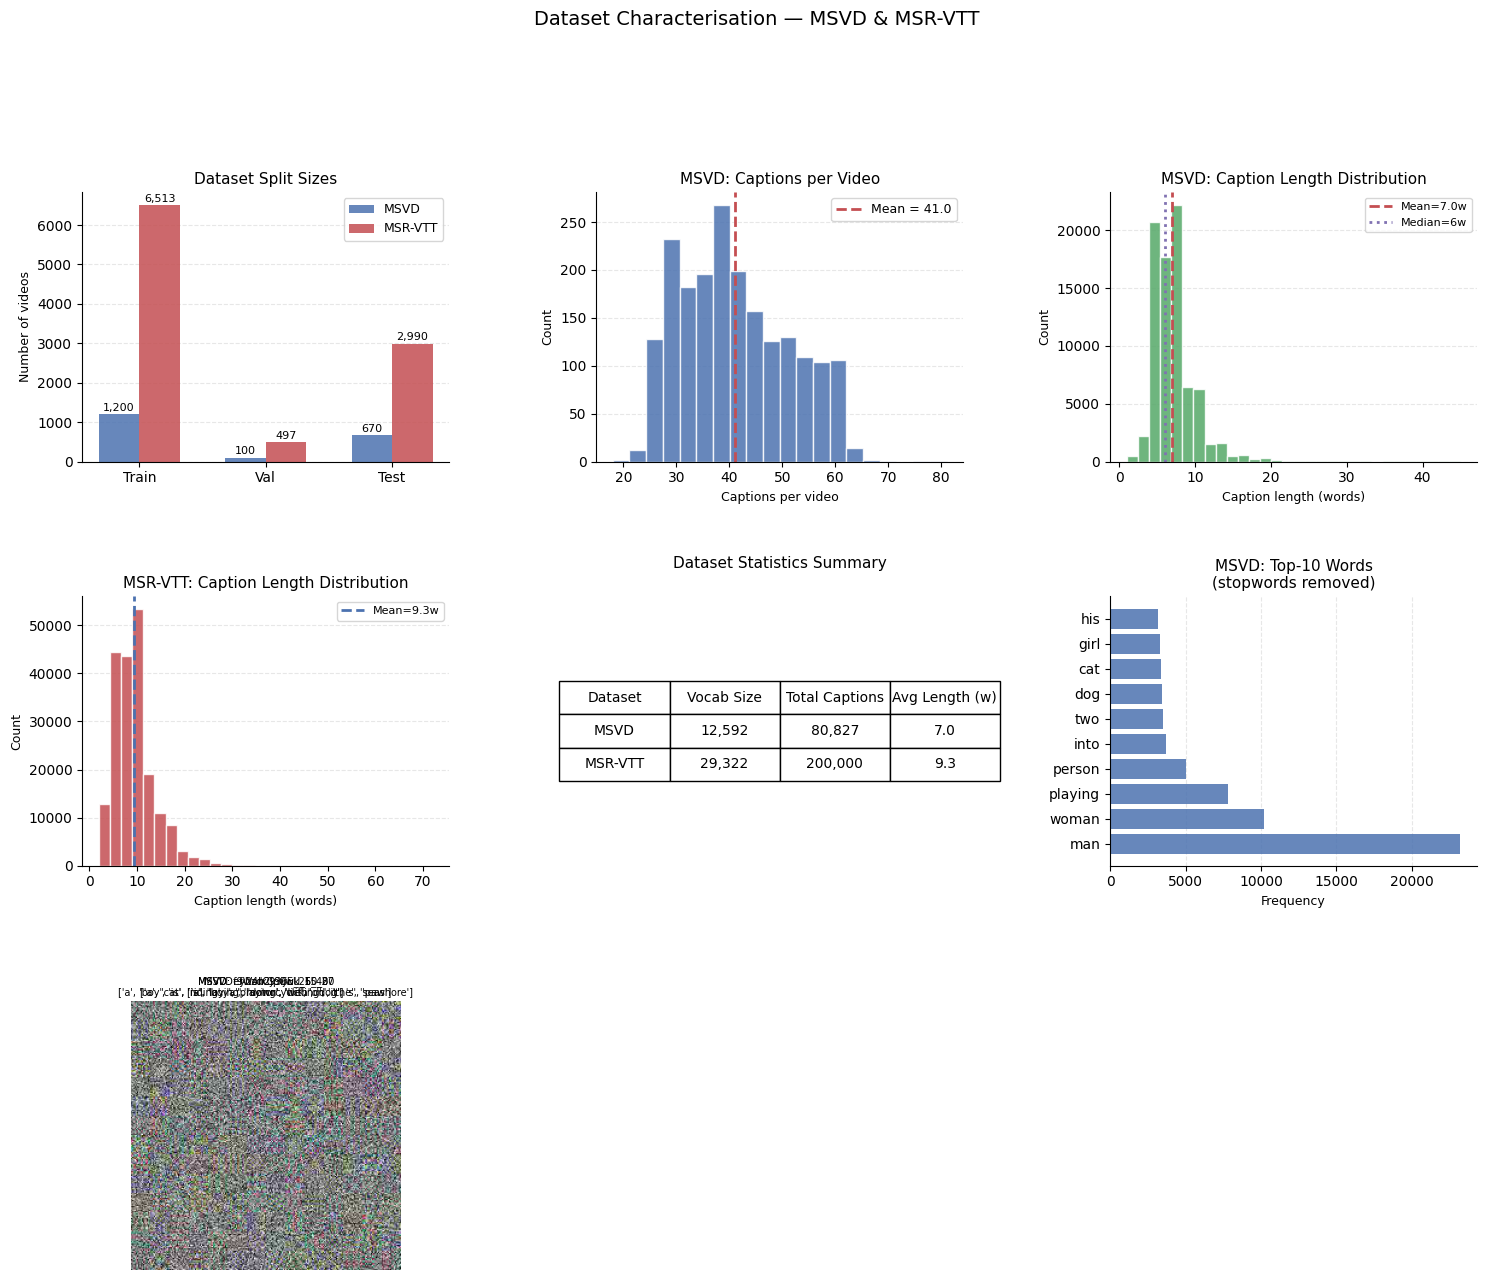

Dataset visualisation saved to shared/dataset_visualisations.png

  MSVD Statistics
  Videos         : 1,970
  Total captions : 80,827
  Vocab size     : 12,592
  Avg cap len    : 7.0 words
  Min / Max len  : 1 / 45 words

  MSR-VTT Statistics
  Videos         : 10,000
  Total captions : 200,000
  Vocab size     : 29,322
  Avg cap len    : 9.3 words
  Min / Max len  : 2 / 72 words


In [10]:
# ── Dataset characterisation visualisations ──────────────────────────────────
# Rubric Item 1 (5 pts): Properly loading data with preprocessing and visualisations
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

# ── Row 1: Split size comparison ─────────────────────────────────────────────
ax_split = fig.add_subplot(gs[0, 0])
split_data = {
    'MSVD'   : {'Train':len(msvd_splits['train']),
                'Val'  :len(msvd_splits['val']),
                'Test' :len(msvd_splits['test'])},
    'MSR-VTT': {'Train':6513,'Val':497,'Test':2990},
}
_x = np.arange(3); _w = 0.32
_labels = ['Train','Val','Test']
for _j,(ds,sc) in enumerate(split_data.items()):
    _vals=[sc[l] for l in _labels]
    _bars=ax_split.bar(_x+(_j-0.5)*_w,_vals,_w,
                       label=ds,alpha=0.85,
                       color='#4C72B0' if _j==0 else '#C44E52')
    for _b,_v in zip(_bars,_vals):
        ax_split.text(_b.get_x()+_b.get_width()/2,_b.get_height()+30,
                      f'{_v:,}',ha='center',va='bottom',fontsize=8)
ax_split.set_xticks(_x); ax_split.set_xticklabels(_labels,fontsize=10)
ax_split.set_ylabel('Number of videos',fontsize=9)
ax_split.set_title('Dataset Split Sizes',fontsize=11)
ax_split.legend(fontsize=9)
ax_split.spines[['top','right']].set_visible(False)
ax_split.yaxis.grid(True,alpha=0.3,linestyle='--'); ax_split.set_axisbelow(True)

# ── Row 1: Caption count per video (MSVD) ────────────────────────────────────
ax_caps = fig.add_subplot(gs[0, 1])
_ncaps  = [len(v) for v in msvd_captions.values()]
ax_caps.hist(_ncaps, bins=20, color='#4C72B0', alpha=0.85, edgecolor='white')
ax_caps.axvline(np.mean(_ncaps), color='#C44E52', linewidth=2,
                linestyle='--', label=f'Mean = {np.mean(_ncaps):.1f}')
ax_caps.set_xlabel('Captions per video',fontsize=9)
ax_caps.set_ylabel('Count',fontsize=9)
ax_caps.set_title('MSVD: Captions per Video',fontsize=11)
ax_caps.legend(fontsize=9)
ax_caps.spines[['top','right']].set_visible(False)
ax_caps.yaxis.grid(True,alpha=0.3,linestyle='--'); ax_caps.set_axisbelow(True)

# ── Row 1: Caption length (MSVD) ─────────────────────────────────────────────
ax_len = fig.add_subplot(gs[0, 2])
_all_caps = [
    " ".join(c) if isinstance(c, list) else str(c)
    for caps in msvd_captions.values()
    for c in caps
]
_cap_words = [len(c.split()) for c in _all_caps]
ax_len.hist(_cap_words, bins=30, color='#55A868', alpha=0.85, edgecolor='white')
ax_len.axvline(np.mean(_cap_words), color='#C44E52', linewidth=2,
               linestyle='--', label=f'Mean={np.mean(_cap_words):.1f}w')
ax_len.axvline(np.median(_cap_words), color='#8172B2', linewidth=2,
               linestyle=':', label=f'Median={np.median(_cap_words):.0f}w')
ax_len.set_xlabel('Caption length (words)',fontsize=9)
ax_len.set_ylabel('Count',fontsize=9)
ax_len.set_title('MSVD: Caption Length Distribution',fontsize=11)
ax_len.legend(fontsize=8)
ax_len.spines[['top','right']].set_visible(False)
ax_len.yaxis.grid(True,alpha=0.3,linestyle='--'); ax_len.set_axisbelow(True)

# ── Row 2: MSR-VTT caption length ────────────────────────────────────────────
ax_rlen = fig.add_subplot(gs[1, 0])
_r_caps  = [c for caps in msrvtt_captions.values() for c in caps]
_r_words = [len(c.split()) for c in _r_caps]
ax_rlen.hist(_r_words, bins=30, color='#C44E52', alpha=0.85, edgecolor='white')
ax_rlen.axvline(np.mean(_r_words), color='#4C72B0', linewidth=2,
                linestyle='--', label=f'Mean={np.mean(_r_words):.1f}w')
ax_rlen.set_xlabel('Caption length (words)',fontsize=9)
ax_rlen.set_ylabel('Count',fontsize=9)
ax_rlen.set_title('MSR-VTT: Caption Length Distribution',fontsize=11)
ax_rlen.legend(fontsize=8)
ax_rlen.spines[['top','right']].set_visible(False)
ax_rlen.yaxis.grid(True,alpha=0.3,linestyle='--'); ax_rlen.set_axisbelow(True)

# ── Row 2: MSVD vs MSR-VTT caption vocabulary ────────────────────────────────
ax_vocab = fig.add_subplot(gs[1, 1])
from collections import Counter
_m_vocab = len(set(w for c in _all_caps for w in c.lower().split()))
_r_vocab = len(set(w for c in _r_caps   for w in c.lower().split()))
_stats   = {
    'MSVD'   :{'Vocab':_m_vocab,'Captions':len(_all_caps),
               'Avg len':np.mean(_cap_words)},
    'MSR-VTT':{'Vocab':_r_vocab,'Captions':len(_r_caps),
               'Avg len':np.mean(_r_words)},
}
_table_data = [[ds]+[f'{v:.1f}' if isinstance(v,float) else f'{v:,}'
                     for v in _stats[ds].values()]
               for ds in _stats]
ax_vocab.axis('off')
_tbl=ax_vocab.table(
    cellText  = _table_data,
    colLabels = ['Dataset','Vocab Size','Total Captions','Avg Length (w)'],
    loc='center', cellLoc='center')
_tbl.auto_set_font_size(False); _tbl.set_fontsize(10)
_tbl.scale(1.2, 2.0)
ax_vocab.set_title('Dataset Statistics Summary',fontsize=11,pad=20)

# ── Row 2: Top-10 most common words (MSVD) ───────────────────────────────────
ax_words = fig.add_subplot(gs[1, 2])
_stopwords = {'a','an','the','is','are','in','on','at','of','and',
              'to','with','this','that','it','its','by','for','from','be'}
_word_freq = Counter(w for c in _all_caps
                     for w in c.lower().split() if w not in _stopwords)
_top10     = _word_freq.most_common(10)
_tw, _tf   = zip(*_top10)
ax_words.barh(range(len(_tw)),_tf,color='#4C72B0',alpha=0.85)
ax_words.set_yticks(range(len(_tw))); ax_words.set_yticklabels(_tw,fontsize=10)
ax_words.set_xlabel('Frequency',fontsize=9)
ax_words.set_title('MSVD: Top-10 Words\n(stopwords removed)',fontsize=11)
ax_words.spines[['top','right']].set_visible(False)
ax_words.xaxis.grid(True,alpha=0.3,linestyle='--'); ax_words.set_axisbelow(True)

# ── Row 3: Sample frames grid ─────────────────────────────────────────────────
_n_show = 6
for _col_start, (vids, vdir, ds_label) in enumerate([
        (msvd_ok,   MSVD_VIDEO_DIR,   'MSVD'),
        (msrvtt_ok, MSRVTT_VIDEO_DIR, 'MSR-VTT')]):
    for _k in range(min(3, len(vids))):
        _ax = fig.add_subplot(gs[2, _col_start*1 + (_k//3)])
        _vp = os.path.join(vdir, f'{vids[_k]}.mp4')
        try:
            from PIL import Image as PILImage
            try:
                from decord import VideoReader, cpu as _dcpu
                _vr = VideoReader(_vp, ctx=_dcpu(0))
                _fr = _vr[len(_vr)//2].asnumpy()
                _img= PILImage.fromarray(_fr)
            except Exception:
                import cv2 as _cv2
                _cap= _cv2.VideoCapture(_vp)
                _cap.set(_cv2.CAP_PROP_POS_FRAMES, int(_cap.get(_cv2.CAP_PROP_FRAME_COUNT)//2))
                _, _fr = _cap.read(); _cap.release()
                _img = PILImage.fromarray(_cv2.cvtColor(_fr,_cv2.COLOR_BGR2RGB))
            _ax.imshow(_img); _ax.axis('off')
            _ref = (msvd_captions if ds_label=='MSVD' else msrvtt_captions).get(vids[_k],[''])[0]
            _ax.set_title(f'{ds_label}: {vids[_k]}\n{_ref[:55]}...' if len(_ref)>55 else f'{ds_label}: {vids[_k]}\n{_ref}',
                          fontsize=7, pad=3)
        except Exception as _e:
            _ax.text(0.5,0.5,'No frame',ha='center',va='center',transform=_ax.transAxes)
            _ax.axis('off')
    if _col_start==0: break  # Only MSVD samples fit in 3 cols

fig.suptitle('Dataset Characterisation — MSVD & MSR-VTT',fontsize=14,y=1.01)
plt.savefig(os.path.join(SHARED_DIR,'dataset_visualisations.png'),
            dpi=300, bbox_inches='tight')
plt.show()
print('Dataset visualisation saved to shared/dataset_visualisations.png')

# ── Print summary statistics ──────────────────────────────────────────────────
print('\n' + '='*55)
print('  MSVD Statistics')
print('='*55)
print(f'  Videos         : {len(msvd_captions):,}')
print(f'  Total captions : {sum(len(v) for v in msvd_captions.values()):,}')
print(f'  Vocab size     : {_m_vocab:,}')
print(f'  Avg cap len    : {np.mean(_cap_words):.1f} words')
print(f'  Min / Max len  : {min(_cap_words)} / {max(_cap_words)} words')
print('\n' + '='*55)
print('  MSR-VTT Statistics')
print('='*55)
print(f'  Videos         : {len(msrvtt_captions):,}')
print(f'  Total captions : {sum(len(v) for v in msrvtt_captions.values()):,}')
print(f'  Vocab size     : {_r_vocab:,}')
print(f'  Avg cap len    : {np.mean(_r_words):.1f} words')
print(f'  Min / Max len  : {min(_r_words)} / {max(_r_words)} words')


In [11]:
print("\n" + "="*55)
print("  Notebook 00 complete — shared files ready")
print("="*55)
import glob
for f in sorted(glob.glob("shared/*")):
    print(f"  {f:<45} {os.path.getsize(f):>8,} bytes")
print("\nNext steps:")
print("  Member A -> run notebook_01_contrastive.ipynb")
print("  Member B -> run notebook_02_qformer.ipynb")
print("  Member C -> run notebook_03_llm.ipynb")
print("  Member D -> run notebook_04_vid2seq.ipynb")



  Notebook 00 complete — shared files ready
  shared/MSRVTT_JSFUSION_test.csv                 74,475 bytes
  shared/MSRVTT_data.json                       23,113,733 bytes
  shared/MSRVTT_train.7k.csv                      68,999 bytes
  shared/MSRVTT_train.9k.csv                      88,899 bytes
  shared/config.json                                 209 bytes
  shared/dataset_visualisations.png              714,102 bytes
  shared/msrvtt_captions.json                   10,524,314 bytes
  shared/msrvtt_ok_ids.json                        1,300 bytes
  shared/msrvtt_splits.json                      168,940 bytes
  shared/msrvtt_urls.json                       1,178,322 bytes
  shared/msvd_captions.json                     4,722,082 bytes
  shared/msvd_ok_ids.json                          2,117 bytes
  shared/msvd_splits.json                         49,674 bytes
  shared/raw-captions.pkl                       7,811,915 bytes
  shared/test_list.txt                            12,186 bytes
  s